# E2–E4 results and INC-02 / INC-03 evidence

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works when started from the repository root or from analysis/.
ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
OUT = ROOT / "analysis" / "figures_cimy"
OUT.mkdir(parents=True, exist_ok=True)

AFTER = "c735d0c"  # code version with all four fixes
CANDIDATES = ["unsorted_list", "sorted_list", "hash_table", "avl_tree", "bplus_tree"]
REFS = ["ref_dict", "ref_bisect"]
STYLE = {"ref_dict": ":", "ref_bisect": ":"}

df = pd.read_csv(ROOT / "results" / "timings.csv")
df["us_per_op"] = df["total_ns"] / df["n_ops"] / 1000


def iqr_line(ax, g, x, label, ls="-"):
    """Plot the median with a shaded band from Q1 to Q3."""
    q = g.groupby(x)["us_per_op"].quantile([0.25, 0.5, 0.75]).unstack()
    line, = ax.plot(q.index, q[0.5], marker="o", ms=4, ls=ls, label=label)
    ax.fill_between(q.index, q[0.25], q[0.75], alpha=0.2, color=line.get_color())


def slope(g, x):
    """Log-log slope of the median time per query against x."""
    med = g.groupby(x)["us_per_op"].median()
    return np.polyfit(np.log(med.index), np.log(med.values), 1)[0]


def summary(g, by):
    """Median [Q1, Q3] of µs per query, as text, for each value of `by`."""
    return g.groupby(by)["us_per_op"].apply(
        lambda v: f"{v.median():.2f} [{v.quantile(.25):.2f}, {v.quantile(.75):.2f}]")

## E2: point lookups on `track_id`

How does lookup cost grow with n, and do hits and misses differ? The table gives µs per query at n = 114,000, the log-log slope over the six sizes, and the comparisons per query.

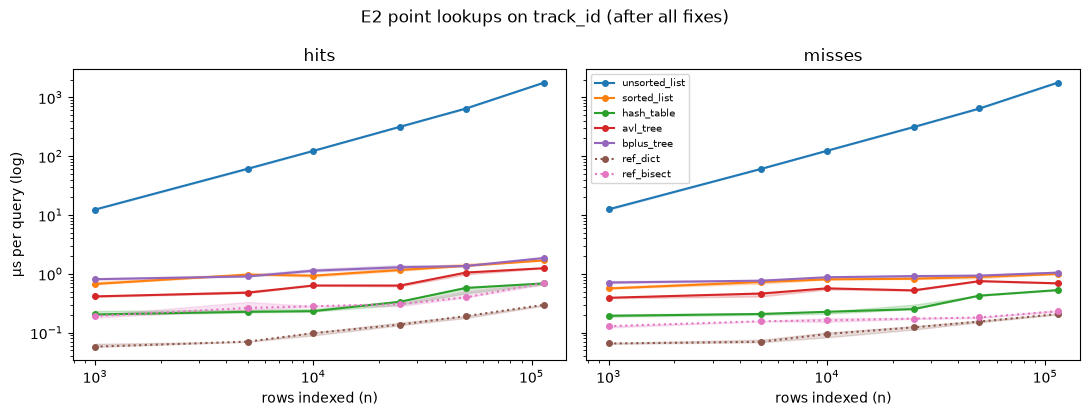

,operation,index,us/query @114k,slope,comparisons/query
0,point_hit,unsorted_list,"1776.67 [1775.53, 1784.40]",1.04,114000.0
1,point_hit,sorted_list,"1.69 [1.69, 1.74]",0.19,17.5
2,point_hit,hash_table,"0.69 [0.66, 0.69]",0.28,1.3
3,point_hit,avl_tree,"1.25 [1.24, 1.28]",0.24,15.9
4,point_hit,bplus_tree,"1.86 [1.75, 1.87]",0.17,16.8
5,point_hit,ref_dict,"0.30 [0.29, 0.30]",0.35,NaN
6,point_hit,ref_bisect,"0.70 [0.66, 0.72]",0.24,NaN
7,point_miss,unsorted_list,"1776.23 [1771.63, 1779.56]",1.04,114000.0
8,point_miss,sorted_list,"0.99 [0.99, 1.02]",0.11,16.2
9,point_miss,hash_table,"0.53 [0.52, 0.54]",0.22,0.7


In [2]:
e2 = df[(df.experiment == "E2_point_track_id") & (df.code_version == AFTER)]
rows = []
for op in ["point_hit", "point_miss"]:
    for name in CANDIDATES + REFS:
        g = e2[(e2.index_type == name) & (e2.operation == op)]
        big = g[g.n_keys == 114000]
        rows.append({"operation": op, "index": name,
                     "us/query @114k": summary(big, "n_keys").iloc[0],
                     "slope": round(slope(g, "n_keys"), 2),
                     "comparisons/query": round((big.comparisons / big.n_ops).median(), 1)})
e2_table = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, op in zip(axes, ["point_hit", "point_miss"]):
    for name in CANDIDATES + REFS:
        iqr_line(ax, e2[(e2.index_type == name) & (e2.operation == op)], "n_keys", name, STYLE.get(name, "-"))
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title("hits" if op == "point_hit" else "misses")
    ax.set_xlabel("rows indexed (n)")
axes[0].set_ylabel("µs per query (log)")
axes[1].legend(fontsize=7)
fig.suptitle("E2 point lookups on track_id (after all fixes)")
fig.tight_layout(); fig.savefig(OUT / "E2_point_lookup.png", dpi=150)
plt.show()
e2_table

## E3: range queries on `tempo`

How does range-query cost depend on the share of distinct tempos the range covers? µs per query, median [Q1, Q3].

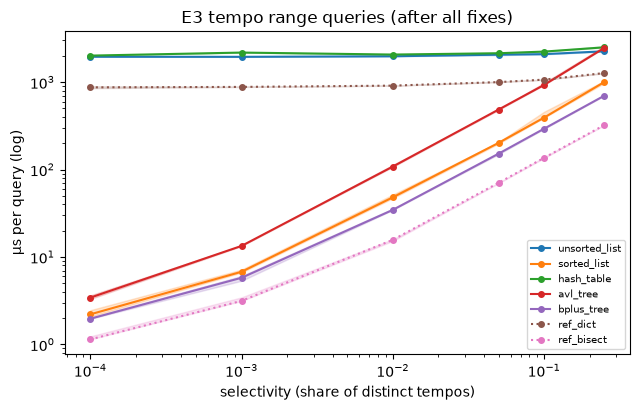

,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
selectivity,,,,,,,
0.0001,"1952.47 [1951.20, 1953.33]","2.21 [2.08, 2.46]","2012.33 [2012.30, 2022.43]","3.43 [3.31, 3.64]","1.97 [1.97, 2.03]","872.24 [853.96, 896.70]","1.14 [1.14, 1.24]"
0.0010,"1948.27 [1947.00, 1960.10]","6.78 [6.64, 7.18]","2180.12 [2178.72, 2190.63]","13.40 [13.34, 13.52]","5.79 [5.34, 6.07]","882.38 [881.39, 889.97]","3.15 [3.14, 3.46]"
0.0100,"1977.47 [1976.57, 1989.95]","48.19 [47.08, 51.78]","2069.14 [2069.03, 2079.26]","108.34 [107.38, 113.01]","34.60 [34.58, 35.75]","912.53 [910.36, 914.55]","15.71 [15.25, 15.95]"
0.0500,"2062.03 [2036.57, 2082.66]","202.09 [197.98, 206.03]","2142.18 [2113.03, 2158.41]","485.77 [481.96, 486.68]","152.08 [149.78, 152.31]","1001.65 [1001.05, 1014.82]","70.51 [69.79, 70.65]"
0.1000,"2092.18 [2082.44, 2092.90]","393.23 [391.51, 458.80]","2237.56 [2229.82, 2247.25]","930.23 [928.85, 982.99]","293.55 [292.51, 295.51]","1069.14 [1064.34, 1070.83]","136.40 [135.29, 138.97]"
0.2500,"2255.63 [2240.51, 2261.42]","1003.49 [976.93, 1035.89]","2503.23 [2497.56, 2581.37]","2464.67 [2464.52, 2591.87]","700.32 [699.85, 710.27]","1271.64 [1261.45, 1279.78]","322.53 [321.77, 323.64]"


In [3]:
e3 = df[(df.experiment == "E3_range_tempo") & (df.code_version == AFTER)]
e3_table = pd.DataFrame({name: summary(e3[e3.index_type == name], "operation_param")
                         for name in CANDIDATES + REFS})
e3_table.index.name = "selectivity"

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for name in CANDIDATES + REFS:
    iqr_line(ax, e3[e3.index_type == name], "operation_param", name, STYLE.get(name, "-"))
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("selectivity (share of distinct tempos)")
ax.set_ylabel("µs per query (log)")
ax.set_title("E3 tempo range queries (after all fixes)")
ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(OUT / "E3_range_tempo.png", dpi=150)
plt.show()
e3_table

## E4: prefix search on `track_name`

How does prefix-search cost depend on prefix length? µs per query, median [Q1, Q3]. The second table gives the keys examined per query, which shows how many titles each prefix matches.

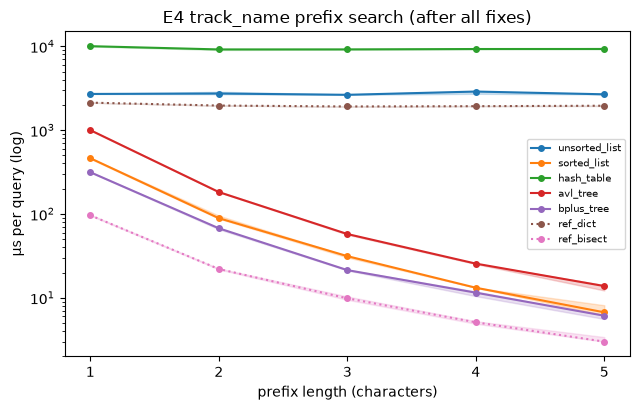

,unsorted_list,sorted_list,hash_table,avl_tree,bplus_tree,ref_dict,ref_bisect
prefix length,,,,,,,
1.0,"2699.50 [2696.59, 2705.10]","462.18 [455.45, 465.14]","10035.45 [9950.61, 10049.57]","999.21 [989.56, 1007.73]","314.30 [313.78, 319.23]","2125.82 [2122.32, 2127.60]","96.24 [95.63, 97.98]"
2.0,"2732.92 [2680.62, 2868.53]","88.94 [87.83, 95.49]","9175.03 [9036.52, 9215.31]","182.20 [181.87, 186.52]","67.40 [65.57, 67.60]","1963.64 [1960.30, 1966.01]","22.03 [21.80, 22.36]"
3.0,"2637.07 [2634.75, 2661.19]","31.36 [30.23, 31.37]","9186.65 [9122.55, 9211.73]","57.59 [56.60, 57.89]","21.36 [21.16, 21.60]","1914.70 [1911.85, 1914.87]","9.84 [9.44, 10.36]"
4.0,"2884.67 [2711.08, 2924.60]","13.16 [13.15, 13.21]","9278.97 [9234.56, 9303.49]","25.53 [25.21, 25.58]","11.49 [10.45, 11.88]","1929.12 [1928.62, 1947.81]","5.09 [4.89, 5.24]"
5.0,"2674.26 [2666.66, 2677.48]","6.70 [6.21, 8.14]","9285.42 [9255.00, 9536.45]","13.78 [12.22, 14.15]","6.10 [5.58, 6.16]","1953.75 [1939.77, 1958.01]","2.99 [2.99, 3.39]"


index_type,avl_tree,bplus_tree,hash_table,sorted_list,unsorted_list
operation_param,,,,,
1.0,3261.0,3262.0,72396.0,3262.0,113999.0
2.0,602.0,603.0,72396.0,603.0,113999.0
3.0,213.0,214.0,72396.0,214.0,113999.0
4.0,97.0,98.0,72396.0,98.0,113999.0
5.0,42.0,43.0,72396.0,43.0,113999.0


In [4]:
e4 = df[(df.experiment == "E4_prefix_track_name") & (df.code_version == AFTER)]
e4_table = pd.DataFrame({name: summary(e4[e4.index_type == name], "operation_param")
                         for name in CANDIDATES + REFS})
e4_table.index.name = "prefix length"
e4_keys = (e4[e4.index_type.isin(CANDIDATES)]
           .assign(keys=lambda t: t.comparisons / t.n_ops)
           .groupby(["operation_param", "index_type"])["keys"].median().unstack().round(0))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for name in CANDIDATES + REFS:
    iqr_line(ax, e4[e4.index_type == name], "operation_param", name, STYLE.get(name, "-"))
ax.set_yscale("log"); ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("prefix length (characters)")
ax.set_ylabel("µs per query (log)")
ax.set_title("E4 track_name prefix search (after all fixes)")
ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(OUT / "E4_prefix_track_name.png", dpi=150)
plt.show()
display(e4_table)
e4_keys

## INC-02: hash table growth

Before: `03d990e` (adds 1,024 buckets per resize). After: `c735d0c` (doubles). The CORE panel compares the same machine (cimy-mbp). The E1 panel shows resize counts, which are the same on every machine.

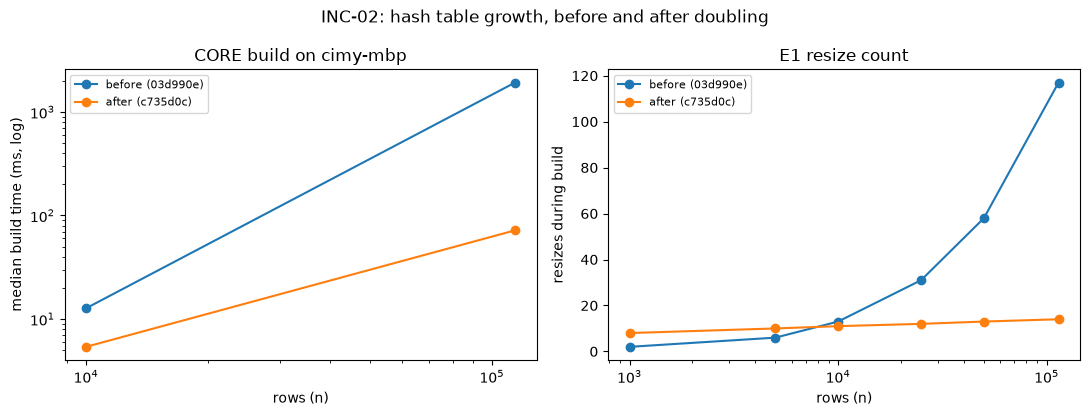

median_ms  resizes
code_version n_keys                    
03d990e      10000       12.71     13.0
             114000    1922.13    117.0
c735d0c      10000        5.39     11.0
             114000      71.89     14.0

In [5]:
core = df[(df.experiment == "CORE") & (df.machine_id == "cimy-mbp") & (df.operation == "build")
          & (df.index_type == "hash_table")]
e1 = df[(df.experiment == "E1_build_memory") & (df.index_type == "hash_table")]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for version, label in [("03d990e", "before (03d990e)"), (AFTER, "after (c735d0c)")]:
    med = core[core.code_version == version].groupby("n_keys")["total_ns"].median() / 1e6
    axes[0].plot(med.index, med.values, marker="o", label=label)
    med = e1[e1.code_version == version].groupby("n_keys")["resizes"].median()
    axes[1].plot(med.index, med.values, marker="o", label=label)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("rows (n)"); axes[0].set_ylabel("median build time (ms, log)")
axes[0].set_title("CORE build on cimy-mbp")
axes[1].set_xscale("log")
axes[1].set_xlabel("rows (n)"); axes[1].set_ylabel("resizes during build")
axes[1].set_title("E1 resize count")
for ax in axes: ax.legend(fontsize=8)
fig.suptitle("INC-02: hash table growth, before and after doubling")
fig.tight_layout(); fig.savefig(OUT / "INC-02_hash_build.png", dpi=150)
plt.show()

core.groupby(["code_version", "n_keys"]).agg(
    median_ms=("total_ns", lambda s: round(s.median() / 1e6, 2)),
    resizes=("resizes", "median"))

## INC-03: AVL rotation height order

Before: `03d990e`. After: `c735d0c`. Rotations per inserted key and tree height for E1 (file order) and E5 (random order). The black line is the AVL height limit 1.44·log2(n + 2).

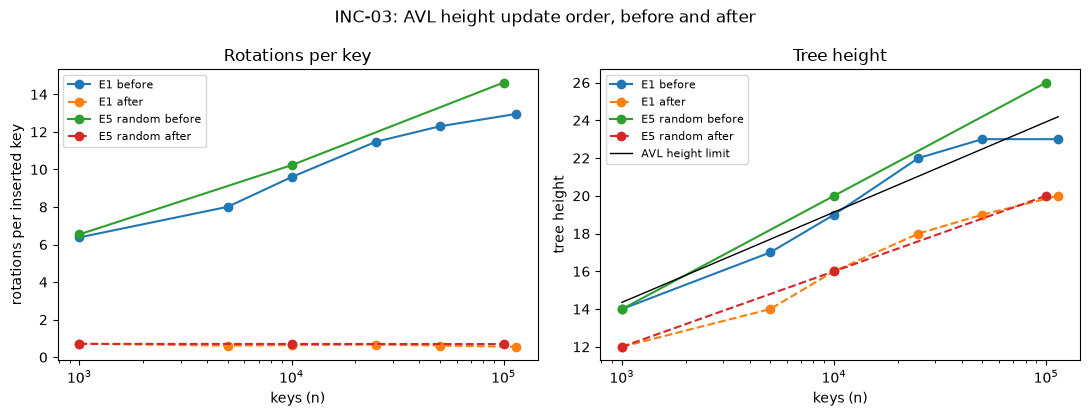

,run,n,rotations/key,height,height limit
0,E1 before,1000,6.380,14.0,14.4
1,E1 before,5000,8.009,17.0,17.7
2,E1 before,10000,9.592,19.0,19.1
3,E1 before,25000,11.474,22.0,21.0
4,E1 before,50000,12.296,23.0,22.5
5,E1 before,114000,12.952,23.0,24.2
6,E1 after,1000,0.718,12.0,14.4
7,E1 after,5000,0.614,14.0,17.7
8,E1 after,10000,0.648,16.0,19.1
9,E1 after,25000,0.669,18.0,21.0


In [6]:
avl = df[(df.index_type == "avl_tree") & (df.operation == "build")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
rows = []
for (exp, version), label in [(("E1_build_memory", "03d990e"), "E1 before"),
                              (("E1_build_memory", AFTER), "E1 after"),
                              (("E5_insert_order", "03d990e"), "E5 random before"),
                              (("E5_insert_order", AFTER), "E5 random after")]:
    g = avl[(avl.experiment == exp) & (avl.code_version == version)]
    if exp == "E5_insert_order":
        g = g[g.insert_order == "random"]
    med = g.groupby("n_keys")[["rotations", "height"]].median()
    ls = "--" if "after" in label else "-"
    axes[0].plot(med.index, med["rotations"] / med.index, marker="o", ls=ls, label=label)
    axes[1].plot(med.index, med["height"], marker="o", ls=ls, label=label)
    for n, r in med.iterrows():
        rows.append({"run": label, "n": n, "rotations/key": round(r.rotations / n, 3),
                     "height": r.height, "height limit": round(1.44 * np.log2(n + 2), 1)})
n = np.logspace(3, np.log10(114000), 50)
axes[1].plot(n, 1.44 * np.log2(n + 2), color="black", lw=1, label="AVL height limit")
for ax in axes: ax.set_xscale("log"); ax.set_xlabel("keys (n)"); ax.legend(fontsize=8)
axes[0].set_ylabel("rotations per inserted key"); axes[0].set_title("Rotations per key")
axes[1].set_ylabel("tree height"); axes[1].set_title("Tree height")
fig.suptitle("INC-03: AVL height update order, before and after")
fig.tight_layout(); fig.savefig(OUT / "INC-03_avl_rotations_height.png", dpi=150)
plt.show()
pd.DataFrame(rows)